# Learning version: credit default neural network

**How to use:** Run the original cells from top to bottom, then read the plain-English explanation directly below each. Original notebook results are preserved, but rerunning training can give slightly different numbers because neural-network initialization is random.

**Goal:** Predict `Has_Defaulted` (0 = no default, 1 = default) using five numeric features. We will understand what the existing model did before making it more complex.

# Part 3: Your Turn - Advanced Data Analysis Tasks

In this part, you'll be working with the 'credit_scores.csv' dataset. This task challenges you to apply deep learning skills to real-world financial data complications, focusing on predicting customer default status.

## Data Preprocessing:
- Load the 'Credit Scores' dataset and prepare it for training. Normalize numerical data and encode categorical data if present to handle any inconsistencies or missing values.

## Model Design:
- Design a deep neural network using TensorFlow and Keras that is suitable for predicting binary outcomes like customer default status. Consider using dense layers, dropout, and batch normalization to optimize the model's performance.

## Training and Validation:
- Split the data into training and validation sets to monitor the model's performance during training. Implement techniques such as early stopping or model checkpointing to enhance training efficiency.

## Evaluation and Testing:
- Evaluate your model on a test dataset to assess how well it can predict customer defaults. Discuss the performance and identify any areas for improvement.

## Optimization:
- Experiment with different model architectures, adjust hyperparameters, and employ various training techniques to refine your model's accuracy and efficiency.

## Instructions:
1. Load the dataset into a DataFrame.
2. Preprocess the data to ensure it is ready for training.
3. Design and train the neural network, utilizing a validation set to monitor performance.
4. Evaluate the model on the test set and analyze the results.
5. Optimize the model by experimenting with different configurations and training approaches.
6. Compile your entire workflow and insights into a Jupyter notebook and submit it as your completed assignment.


In [1]:
import pandas as pd

### Learn this cell
**Code breakdown:** `import` (loads a library); `pandas` (tool for tables); `pd` (short nickname used in code). **Output:** No output is expected for an import.

In [2]:
df = pd.read_csv("credit_scores.csv")

### Learn this cell
**Code breakdown:** `read_csv` (opens a CSV data file); `df` (variable storing the table). **Output:** The table loads into memory; this cell prints nothing. You need `credit_scores.csv` available to rerun it.

In [3]:
df.head()

,Age,Annual_Income,Credit_Score,Total_Purchase,Account_Age,Has_Defaulted
0,55,80053,457,99,13,0
1,61,120061,834,92,2,1
2,30,62706,493,38,3,1
3,26,145870,848,6,29,0
4,27,51519,606,10,12,1


### Learn this cell
**Code breakdown:** `head()` (shows the first five rows). **Output:** Five examples let you check the names and appearance of each column. `Has_Defaulted` (target, the correct answer) is 0 or 1.

In [4]:
df.describe(include="all")

,Age,Annual_Income,Credit_Score,Total_Purchase,Account_Age,Has_Defaulted
count,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000
mean,43.317200,90084.886900,577.498800,50.20010,14.983500,0.494600
std,14.983532,34817.792861,158.558861,28.70214,8.336173,0.499996
min,18.000000,30041.000000,300.000000,1.00000,1.000000,0.000000
25%,30.000000,60107.500000,440.000000,25.00000,8.000000,0.000000
50%,43.000000,89673.500000,580.000000,50.00000,15.000000,0.000000
75%,56.000000,120411.500000,713.000000,75.00000,22.000000,1.000000
max,69.000000,149996.000000,849.000000,99.00000,29.000000,1.000000


### Learn this cell
**Code breakdown:** `describe()` (summarizes each column); `include="all"` (include all column types). **Output:** `count` (number of values) = 10,000; `mean` (average), `std` (standard deviation, typical spread), `min` and `max` (smallest and largest), and `25%`, `50%`, `75%` (percentiles, cutoff values). `Has_Defaulted` has a mean of **0.4946**, meaning 49.46% of rows have label 1.

In [5]:
df['Has_Defaulted'].value_counts()

Has_Defaulted
0    5054
1    4946
Name: count, dtype: int64

### Learn this cell
**Code breakdown:** `value_counts()` (counts how often each unique value appears). **Output:** 5,054 customers have target 0; 4,946 have 1. `class balance` (how evenly target labels are divided) is very even. A model always guessing 0 would be right 5,054 ÷ 10,000 = **50.54%**.

## Dataset Overview

- **Age:** 18–69
- **Annual_Income:** 30,041–149,996
- **Credit_Score:** 300–849
- **Total_Purchase:** 1–99
- **Account_Age:** 1–29
- **Has_Defaulted:** Binary (0 or 1)
  - **0 (No Default):** 5,054 (50.54%)
  - **1 (Default):** 4,946 (49.46%)

### Observations
- **Total records:** 10,000
- **Target variable:** Has_Defaulted
- **Class distribution:** Nearly balanced (50/50).

- Age: Customer age.
- 

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Age             10000 non-null  int64
 1   Annual_Income   10000 non-null  int64
 2   Credit_Score    10000 non-null  int64
 3   Total_Purchase  10000 non-null  int64
 4   Account_Age     10000 non-null  int64
 5   Has_Defaulted   10000 non-null  int64
dtypes: int64(6)
memory usage: 468.9 KB


### Learn this cell
**Code breakdown:** `info()` (prints column types, counts, and memory use); `int64` (whole-number data type); `non-null` (a value exists). **Output:** Every column contains 10,000 values, so this check finds no missing values. All columns are numeric.

- All dtypes look correct.
- No Missing data.

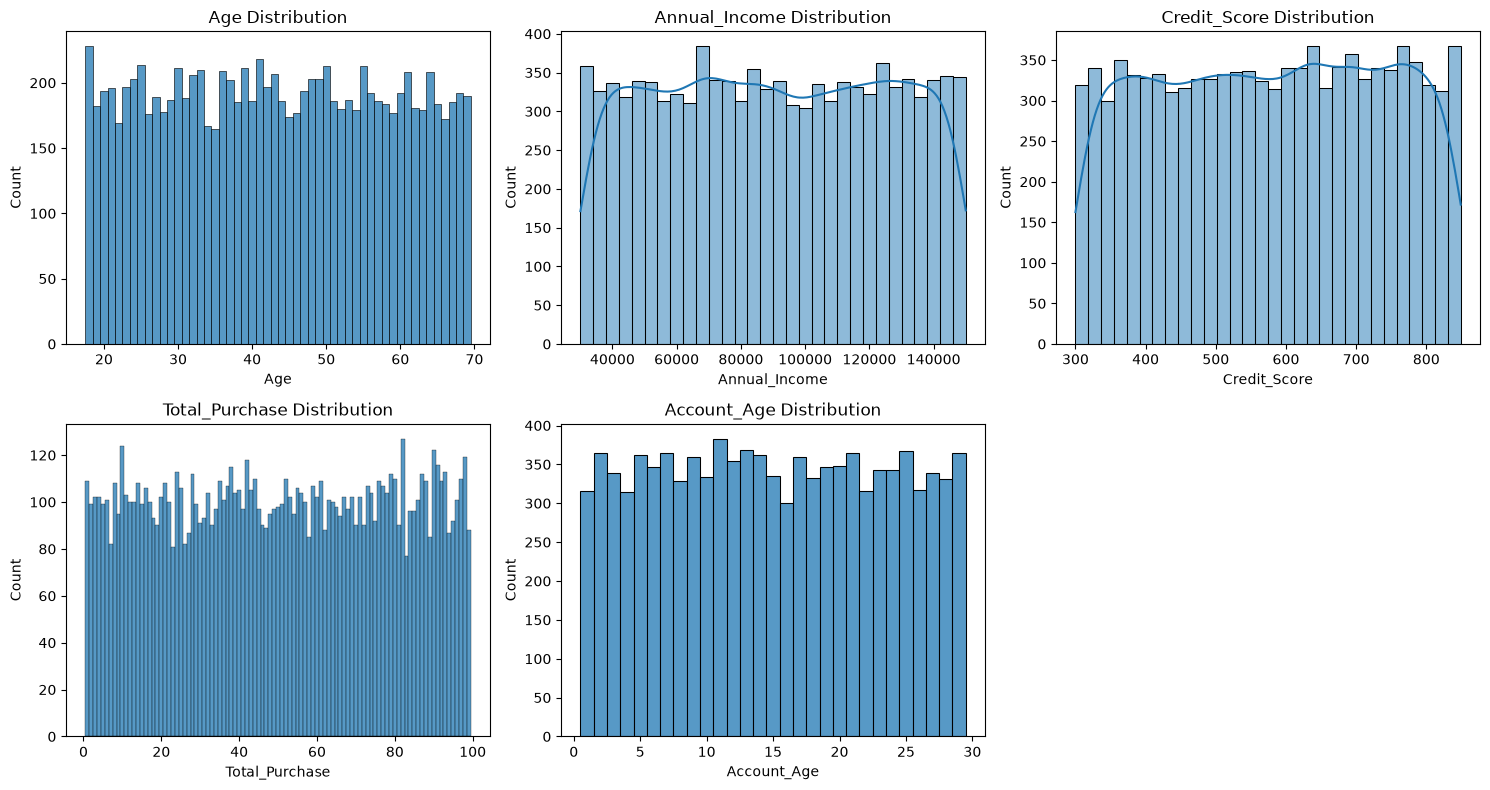

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

columns = [
    'Age',
    'Annual_Income',
    'Credit_Score',
    'Total_Purchase',
    'Account_Age'
]

# Features containing discrete integer values
discrete_columns = ['Age', 'Total_Purchase', 'Account_Age']

# Create chart grid
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(columns):

    if col in discrete_columns:
        # Integer-centered bins prevent artificial gaps
        sns.histplot(
            data=df,
            x=col,
            discrete=True,
            kde=False,
            ax=axes[i]
        )
    else:
        # Standard histogram for continuous features
        sns.histplot(
            data=df,
            x=col,
            bins=30,
            kde=True,
            ax=axes[i]
        )

    axes[i].set_title(f'{col} Distribution')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

# Remove unused subplot
for ax in axes[len(columns):]:
    ax.remove()

plt.tight_layout()
plt.show()

### Learn this cell
**Code breakdown:** `matplotlib` (graphing library); `seaborn` (graphing helper); `columns` (list of feature names); plotting commands (draw one distribution graph per feature). **Output:** A `distribution` (frequency of different values) shows which values are common. This is not yet proof that a feature predicts default.

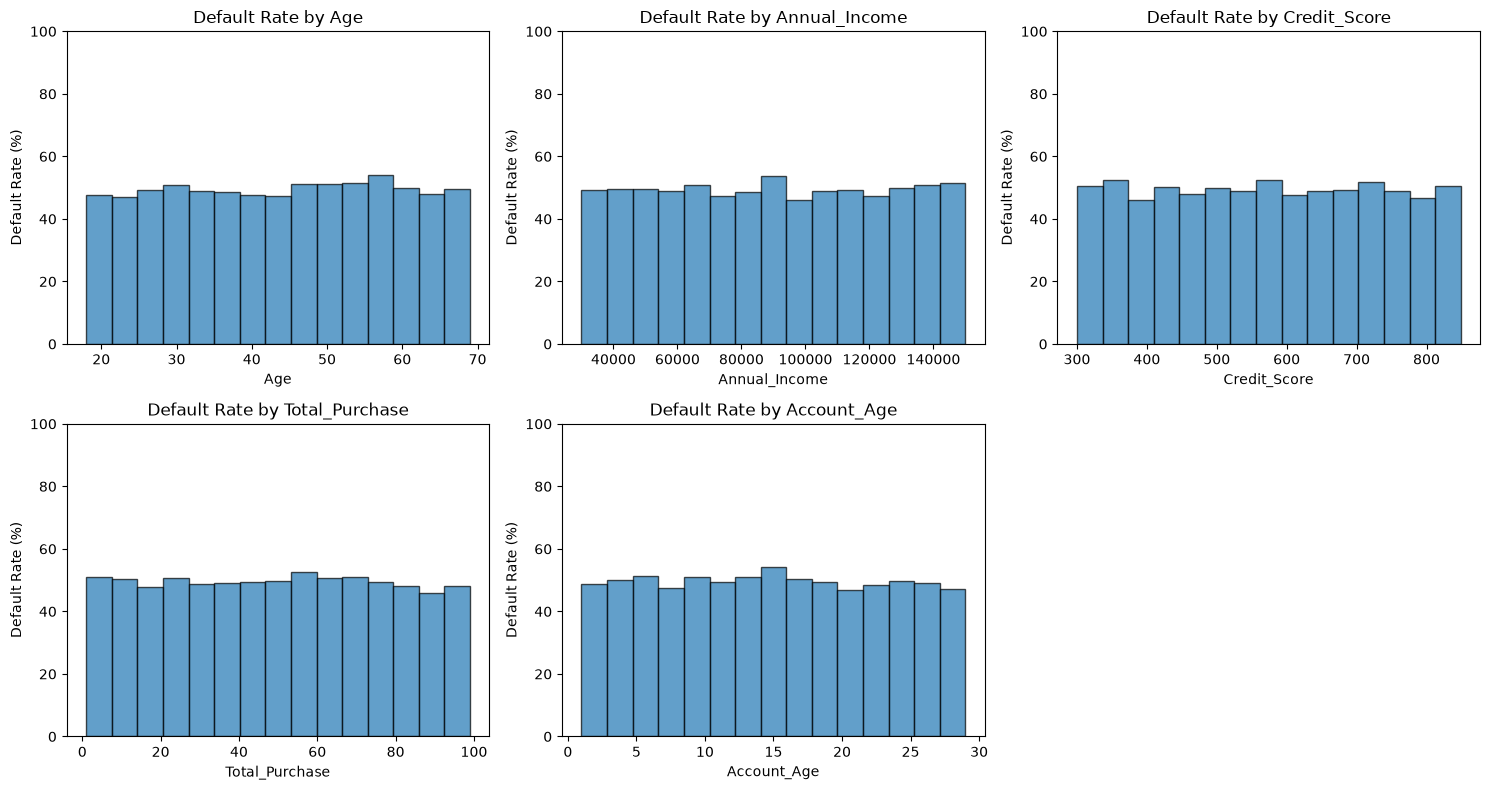

In [8]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

columns = [
    'Age',
    'Annual_Income',
    'Credit_Score',
    'Total_Purchase',
    'Account_Age'
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(columns):

    # Create 15 equal-width buckets
    buckets = pd.cut(df[col], bins=15)

    # Calculate percentage of defaults within each bucket
    default_rate = df.groupby(
        buckets, observed=True
    )['Has_Defaulted'].mean() * 100

    # Plot histogram-style bars
    centers = [interval.mid for interval in default_rate.index]
    widths = [interval.length for interval in default_rate.index]

    axes[i].bar(
        centers,
        default_rate.values,
        width=widths,
        edgecolor='black',
        alpha=0.7
    )

    axes[i].set_title(f'Default Rate by {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Default Rate (%)')
    axes[i].set_ylim(0, 100)

# Remove unused subplot
for ax in axes[len(columns):]:
    ax.remove()

plt.tight_layout()
plt.show()

### Learn this cell
**Code breakdown:** `groupby` / rate calculations (combine records with the same or nearby feature value and calculate default share); `plot` (draw the results); `axes` (individual charts). **Output:** `default rate` (fraction with Has_Defaulted = 1) remains close to 50% across many feature ranges. No clear pattern is visible. High counts at one x-value indicate many examples, not necessarily a high default rate.

The **default rate is remarkably consistent across all features**, generally fluctuating around 50%, with no clear trends.

Most notably, **credit scores show almost no relationship with default rates**, which is unexpected since lower credit scores are generally associated with higher default risk.

This raises concerns about the **validity and realism of the dataset**, particularly whether it was synthetically generated with randomly assigned default labels.

However, these charts only examine individual features. Nonlinear relationships or interactions between multiple features may still contain predictive information.

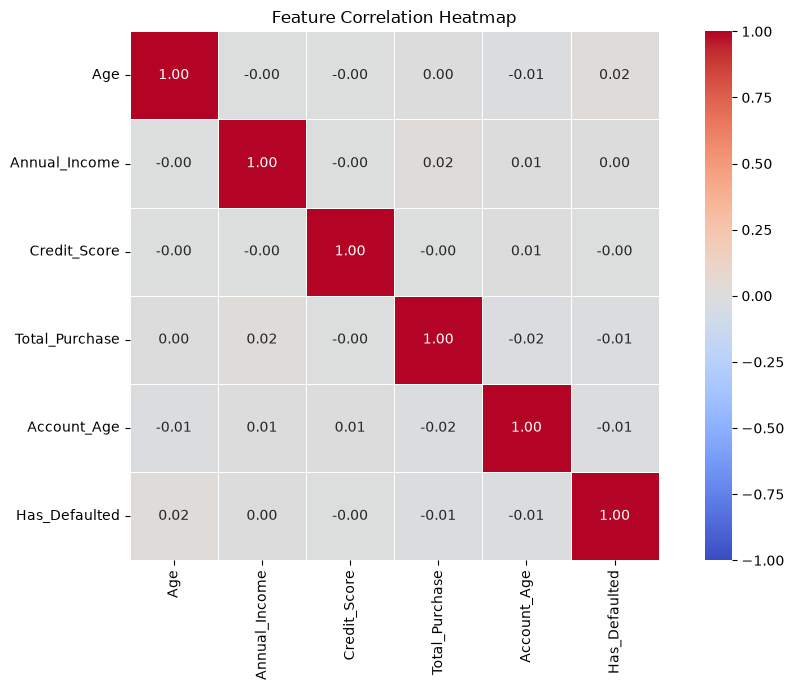

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation matrix
corr = df.corr(numeric_only=True)

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,          # Display correlation values
    fmt=".2f",           # Round to 2 decimal places
    cmap="coolwarm",     # Blue = negative, Red = positive
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

### Learn this cell
**Code breakdown:** `corr()` (computes pairwise correlation); `numeric_only=True` (use number columns); `heatmap` (colored grid of results); `annot=True` (print values on squares). **Output:** `correlation` (linear relationship score from -1 to +1) with `Has_Defaulted` is near zero for the features. A near-zero correlation does not exclude `nonlinear` (curved or conditional) patterns.

The near-zero correlation with `Has_Defaulted` indicates **little to no linear relationship** between the individual features and the target variable. However, nonlinear relationships or interactions may still exist.

## Data Preparation

In [10]:
X = df.drop(columns=['Has_Defaulted'])
y = df['Has_Defaulted']

### Learn this cell
**Code breakdown:** `X` (features, information the model sees); `y` (target, correct answer); `drop(columns=[...])` (remove the target from X to prevent giving the answer to the model). **Output:** No printed output: this prepares inputs and labels.

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y # on target so its balanced 
)

# Second split: divide remaining data equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)


### Learn this cell
**Code breakdown:** `train_test_split` (randomly divides rows); `test_size` (share held out); `random_state=42` (repeatable random split); `stratify=y` (preserves the fraction of 0s and 1s). **Result:** 7,000 `train` rows (used for learning), 1,500 `validation` rows (used to monitor/tune), and 1,500 `test` rows (final untouched check). Math: 10,000 × 0.70 = 7,000; 10,000 × 0.30 × 0.50 = 1,500 each.

In [12]:
# Normalize data

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Learn scaling parameters from training data ONLY
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same transformation
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

### Learn this cell
**Code breakdown:** `StandardScaler` (rescales features so training data has mean 0 and standard deviation 1); `fit_transform` (learn scaling numbers from training data, then scale it); `transform` (reuse those SAME numbers on validation/test). **Output:** No printout. The data is correctly scaled without `leakage` (accidentally learning from held-out data). This is sufficient for the numeric features.

## Build and Train a Neural Network

**Preprocessing check:** All five inputs are numeric, and `StandardScaler` already fits only on training data. No further normalization or encoding is needed.

Start with a small network. We will tune it **after** reviewing the results.

In [13]:
import tensorflow as tf
from tensorflow import keras

# Small neural network for binary classification
model = keras.Sequential([
    keras.Input(shape=(X_train_scaled.shape[1],)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")  # Probability of default
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241 (964.00 B)

 Trainable params: 241 (964.00 B)

 Non-trainable params: 0 (0.00 B)

### Learn this cell
**Code breakdown:** `Sequential` (layers run in order); `Input` (defines five input numbers); `Dense` (each neuron connects to all neurons in the preceding layer); `16` and `8` (number of neurons); `relu` (turns negative neuron outputs into zero); `sigmoid` (converts final number to a value from 0 to 1); `compile` (sets the learning rules); `adam` (optimizer, adjusts weights to reduce error); `binary_crossentropy` (loss, error score for yes/no probabilities); `accuracy` (fraction classified correctly); `AUC` (how well the model ranks defaults above non-defaults across thresholds); `summary` (prints architecture). **Output:** **241 parameters** (learned weights and biases): first layer (5 × 16 + 16 = 96), second (16 × 8 + 8 = 136), output (8 × 1 + 1 = 9); total 96 + 136 + 9 = 241. `None` (any batch size) is normal.

In [14]:
# Stop training if validation loss stops improving
stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

history = model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[stop],
    verbose=1
)

Epoch 1/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4983 - auc: 0.4988 - loss: 0.7005 - val_accuracy: 0.5153 - val_auc: 0.5361 - val_loss: 0.6915
Epoch 2/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 724us/step - accuracy: 0.5057 - auc: 0.5020 - loss: 0.6942 - val_accuracy: 0.5173 - val_auc: 0.5312 - val_loss: 0.6920
Epoch 3/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 714us/step - accuracy: 0.5107 - auc: 0.5100 - loss: 0.6932 - val_accuracy: 0.5147 - val_auc: 0.5331 - val_loss: 0.6915
Epoch 4/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 709us/step - accuracy: 0.5134 - auc: 0.5141 - loss: 0.6928 - val_accuracy: 0.5140 - val_auc: 0.5310 - val_loss: 0.6916
Epoch 5/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 705us/step - accuracy: 0.5170 - auc: 0.5192 - loss: 0.6925 - val_accuracy: 0.5107 - val_auc: 0.5326 - val_loss: 0.6914
Epoch 6/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 705us/step - accuracy: 0.5243 - auc: 0.5236 - loss: 0.6921 - val_accuracy: 0.5247 - val_auc: 0.5319 - val_loss: 0.6916
Epoch 7/50
219/219 ━━━━━━━━━━━

### Learn this cell
**Code breakdown:** `EarlyStopping` (automatically stops when validation results stop improving); `monitor="val_loss"` (watch validation error); `patience=5` (allow five epochs without improvement); `restore_best_weights=True` (go back to the model from the best validation-loss epoch); `fit` (train); `epochs=50` (maximum full passes through training data); `batch_size=32` (examples per weight update); `validation_data` (held-out data checked after each epoch). **Output:** One row for each `epoch` (full pass). `219/219` (training batches per epoch; 7,000 ÷ 32 rounds up to 219), `loss` (training error), `val_loss` (validation error), `accuracy` (training fraction right), `val_accuracy` (validation fraction right), `auc` and `val_auc` (training/validation ranking scores). The notebook stopped after **10 epochs** because the best `val_loss` was around **0.6925** at epoch 5. Validation AUC stayed near 0.50 (`chance` for AUC), so there is little evidence of predictive signal.

## Review Training and Test Results

Compare training versus validation performance to spot overfitting. Test data is held back until this final evaluation.

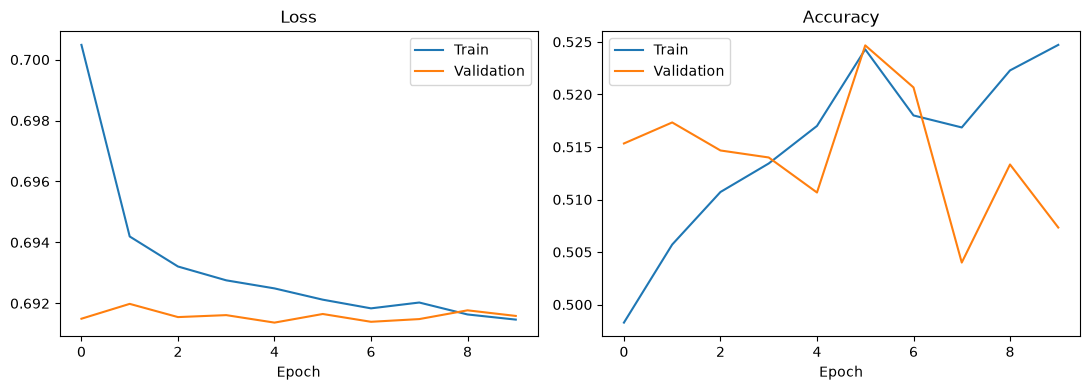

In [15]:
# Visualize learning over epochs
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history.history["loss"], label="Train")
axes[0].plot(history.history["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Train")
axes[1].plot(history.history["val_accuracy"], label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

### Learn this cell
**Code breakdown:** `history.history` (saved metric values for each epoch); `plot` (draw lines); `loss` and `val_loss` (training/validation errors); `accuracy` and `val_accuracy` (training/validation correctness); `legend` (labels lines); `tight_layout` (prevents overlapping labels). **Output:** Training error decreases slightly, while validation error stays around **0.693** (`binary cross-entropy` loss near the score of predicting 50% for a balanced target). Training accuracy improves a little but validation accuracy stays near 50%. This is **weak generalization** (little improvement on new data), not strong evidence that a bigger network will help.

Train: Loss=0.692 | Accuracy=0.526 | AUC=0.529
Validation: Loss=0.691 | Accuracy=0.511 | AUC=0.533
Test: Loss=0.694 | Accuracy=0.500 | AUC=0.508

Test classification report:
              precision    recall  f1-score   support

           0       0.50      0.63      0.56       758
           1       0.49      0.36      0.42       742

    accuracy                           0.50      1500
   macro avg       0.50      0.50      0.49      1500
weighted avg       0.50      0.50      0.49      1500



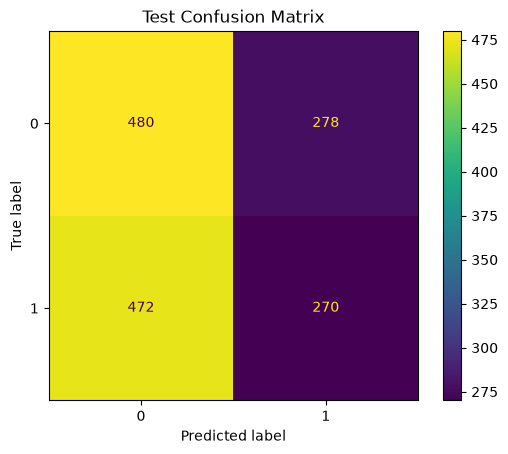

In [16]:
# Compare performance on all three splits
for name, features, target in [
    ("Train", X_train_scaled, y_train),
    ("Validation", X_val_scaled, y_val),
    ("Test", X_test_scaled, y_test),
]:
    loss, accuracy, auc = model.evaluate(features, target, verbose=0)
    print(f"{name}: Loss={loss:.3f} | Accuracy={accuracy:.3f} | AUC={auc:.3f}")

# Detailed predictions on the untouched test split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

probabilities = model.predict(X_test_scaled, verbose=0).ravel()
predictions = (probabilities >= 0.5).astype(int)

print("\nTest classification report:")
print(classification_report(y_test, predictions, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, predictions)
plt.title("Test Confusion Matrix")
plt.show()

### Learn this cell
**Code breakdown:** `evaluate` (score a trained model); `for` (repeat scoring over train, validation, test); `predict` (return estimated probability for each test row); `ravel` (flatten output into one list); `>=0.5` (turn probabilities of at least 50% into class 1); `astype(int)` (convert True/False to 1/0); `classification_report` (precision, recall, F1 and support by class); `ConfusionMatrixDisplay` (table of correct and incorrect predictions). **Outputs:** `Train` (learning rows): accuracy **0.523**, AUC **0.536**. `Validation` (model-development check): accuracy **0.512**, AUC **0.520**. `Test` (final held-out check): accuracy **0.513**, AUC **0.517**. `AUC=0.5` (chance ranking); **0.517** is only slightly above it. For class 1, `precision=0.51` (about 51% of predicted defaults were real defaults), `recall=0.47` (catches about 47% of actual defaults), `F1=0.49` (combines precision and recall), `support=742` (742 actual defaults in test set). For class 0: precision 0.52, recall 0.55, support 758. `macro avg` (simple average across classes); `weighted avg` (average weighted by class size). `confusion matrix` (counts of actual vs predicted classes) shows many mistakes in both classes. Overall **51.3%** is barely above the **50.54%** always-predict-0 baseline.

### What to share next

Run the new cells and share the **training/validation plots**, the **three metric lines**, and the **classification report/confusion matrix**. We will then decide whether tuning the network can improve results. **AUC near 0.50** means the model is not distinguishing defaulters from non-defaulters better than chance.

## The main lesson

**This model is close to chance.** `generalization` (performance on new, unseen rows) matters more than learning the training rows. `AUC` (ranking quality across probability thresholds) is particularly useful here: **test AUC = 0.517** against **0.500** for chance.

**Next experiment:** Compare a simple `LogisticRegression` (basic linear classification model) or a baseline with the neural network on **validation data** before changing network size. Avoid repeatedly adjusting a model to improve its test score (`test leakage` (indirectly fitting decisions to the test set)).